# Baseline Model Tuning: OGBoost (Ordinal Gradient Boosting)
Follow-up to `03_baseline_model_testing.ipynb`, using the same pipeline as `03_2_baseline_model_tuning_lightgbm.ipynb`: score the untuned model, search for better settings, choose the Disrupted threshold, save the results to `results/tuning/ogboost/`.

**What OGBoost is:** gradient boosting for **ordered** labels (`ogboost` package, `GradientBoostingOrdinal`). Instead of one score per status, it learns a single "how bad is this route" score and two cut-off points on that score: below the first cut-off is Normal, between the two is Delayed, above the second is Disrupted. Our labels are ordered (Normal < Delayed < Disrupted), so this uses information the other models ignore: a Disrupted route is treated as "worse than Delayed", not as an unrelated category.

**The test set is still not used.** Same training rows, same 5 folds and same scores as every other tuning notebook (`tuning_setup.py`).

**Why we compare closely with LightGBM:**
- LightGBM was tuned first and set the pipeline every tuning notebook follows: it tied for the best macro-F1 in 03 and was one of our main candidates from the literature review (`03_2_baseline_model_tuning_lightgbm.ipynb`). It is not our single best tuned model (CatBoost is slightly higher: macro-F1 0.610 vs. 0.602), but all tuned models are within about 0.01 macro-F1 of each other (0.598 to 0.610, `results/tuning/*/cv_fold_scores.csv`).
- Both are gradient boosting on trees, so the comparison mainly isolates one difference: treating the labels as **ordered** (OGBoost) vs. as **unrelated classes** (LightGBM).
- Same folds, same threshold method, same pipeline: the two can be compared fold by fold.

## 1. Load Data & Shared Setup
Same as the other tuning notebooks: training rows only, Normal = 0, Delayed = 1, Disrupted = 2, and the same 5 stratified folds as 03.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils.class_weight import compute_sample_weight

# ogboost triggers a harmless scikit-learn deprecation warning when it is imported
warnings.filterwarnings("ignore", message='Value `"friedman_mse"`', category=FutureWarning)
from ogboost import GradientBoostingOrdinal

from tuning_setup import (DISRUPTED, SEARCH_SCORING, STATUS_ORDER, THRESHOLDS, best_threshold_macro_f1,
                          choose_threshold, cross_validated_threshold, load_training_data, make_folds,
                          predict_with_threshold, save_tuning_results, score_folds, score_predictions)

train_df, X_train, y_train = load_training_data()
folds = make_folds(X_train, y_train)

print("Training rows:", len(X_train))
print(f"{X_train.shape[1]} features: {', '.join(X_train.columns)}")
print("Disrupted rows per held-out fold:", [int((y_train.iloc[valid_index] == DISRUPTED).sum()) for _, valid_index in folds])

Training rows: 25040
7 features: geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active
Disrupted rows per held-out fold: [159, 160, 160, 160, 160]


## 2. Starting Point: Untuned OGBoost
Settings: 400 trees and learning rate 0.05 (the same as the boosting models in 03), with OGBoost's own default trees (depth 3) and link function (`probit`, see section 3).

**Class weights:** OGBoost has no `class_weight` option, but its `fit` accepts `sample_weight`. `BalancedOGBoost` below is OGBoost with one change: every time it is trained, it gives each row the **same balanced weight as the other models** (`rows / (3 x rows with that status)`), computed from the rows it is trained on. So each fold, and each model in the search, computes its own weights automatically.

The 5 fold models are trained one at a time here, to time a single fit before running the search.

In [2]:
class BalancedOGBoost(GradientBoostingOrdinal):
    """OGBoost with balanced class weights, computed from the training rows of every fit."""
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced", y))


untuned_model = BalancedOGBoost(base_learner=DecisionTreeRegressor(max_depth=3), n_estimators=400,
                                learning_rate=0.05, link_function="probit", random_state=42)

# Out-of-fold probabilities: each row is predicted by the fold model that didn't see it
untuned_probabilities = np.zeros((len(X_train), len(STATUS_ORDER)))
fit_seconds = []
for train_index, valid_index in folds:
    model = clone(untuned_model)
    start = time.perf_counter()
    model.fit(X_train.iloc[train_index], y_train.iloc[train_index])
    fit_seconds.append(time.perf_counter() - start)
    untuned_probabilities[valid_index] = model.predict_proba(X_train.iloc[valid_index])

print("Columns of predict_proba:", model.classes_, "(0 = Normal, 1 = Delayed, 2 = Disrupted)")
print(f"One fit (400 trees): {np.mean(fit_seconds):.1f} seconds on average")

untuned_fold_scores = score_folds(y_train, untuned_probabilities, folds)
untuned_fold_scores.agg(["mean", "std"]).round(3)

Columns of predict_proba: [0 1 2] (0 = Normal, 1 = Delayed, 2 = Disrupted)
One fit (400 trees): 13.6 seconds on average


,macro_f1,f1_normal,f1_delayed,f1_disrupted,disrupted_precision,disrupted_recall,disrupted_pr_auc,roc_auc_ovr
mean,0.553,0.685,0.686,0.288,0.180,0.723,0.327,0.839
std,0.004,0.004,0.007,0.007,0.005,0.028,0.040,0.003


- **Default rule: macro-F1 0.553 ± 0.004**, lower than untuned LightGBM in 03 (0.581). The class weights push many rows to Disrupted (recall 0.72, precision 0.18).
- **Disrupted PR-AUC 0.327**: above untuned LightGBM (0.295) and equal to *tuned* LightGBM (0.327). So untuned OGBoost already ranks disruptions as well as our best tuned model; it mainly needs its own threshold (sections 6 and 7).
- One 400-tree fit takes about 19 seconds (one core), much slower than LightGBM.

## 3. Search Space
Each boosting round adds one small tree to the "how bad" score, then moves the two cut-off points. These are the settings searched:

| Setting | What it controls | Range searched | Why it matters |
|---|---|---|---|
| `n_estimators` | Number of trees (boosting rounds) | 100 to 1,000 | More trees can learn more, but too many start memorizing noise |
| `learning_rate` | How much each new tree changes the score | 0.005 to 0.3 (log scale) | Smaller steps usually generalize better but need more trees |
| `base_learner__max_depth` | How many questions deep each tree goes | 2, 3, 4, 5, 6, 8 | Deeper trees learn more complex patterns, and overfit more easily |
| `base_learner__min_samples_leaf` | Smallest number of rows allowed in a leaf | 1 to 400 | Large values stop the trees from fitting tiny groups of rows (important for the rare Disrupted class) |
| `base_learner__max_features` | Share of features each split may look at | 0.5 to 1.0 | Less greedy trees, less overfitting |
| `link_function` | Shape of the curve that turns the score into probabilities | `probit`, `logit`, `cauchit` | `cauchit` has heavier tails: more room for extreme (Disrupted) cases |

Fixed settings, and why:
- `subsample=1.0` (every tree sees all rows). In `ogboost` 0.8.4, subsampling **draws rows in proportion to their weight and then applies the weight again**, which would square the class weights.
- `learning_rate_thresh` stays at its default: the cut-off points use a step size that adapts itself every round, so its starting value matters little.
- The `loglog` and `cloglog` links are left out: on our data they crash in `ogboost` 0.8.4 (a numerical overflow gives NaN).

In [3]:
search_space = {
    "n_estimators": randint(100, 1001),
    "learning_rate": loguniform(0.005, 0.3),
    "base_learner__max_depth": [2, 3, 4, 5, 6, 8],
    "base_learner__min_samples_leaf": randint(1, 401),
    "base_learner__max_features": uniform(0.5, 0.5),   # uniform(start, width): 0.5 to 1.0
    "link_function": ["probit", "logit", "cauchit"],
}

base_model = BalancedOGBoost(base_learner=DecisionTreeRegressor(), subsample=1.0, random_state=42)

## 4. Randomized Search
Same setup as LightGBM: **60 combinations**, each scored on the **same 5 folds** (300 models), winner picked by **macro-F1 at its best Disrupted threshold** (`macro_f1_best_threshold`). Default-rule macro-F1, Disrupted PR-AUC and ROC-AUC are recorded too.

**Run time:** one 400-tree fit takes about 19 seconds on one core (section 2), so 300 fits of 100 to 1,000 trees take roughly 15 minutes on a 24-core machine (943 seconds here). That is affordable, so the full 60 combinations are used, as for LightGBM. On a laptop with fewer cores it will take longer; lowering `n_iter` makes it faster. OGBoost has no multi-core option of its own, so `n_jobs=-1` trains one model per core.

In [4]:
search = RandomizedSearchCV(
    base_model,
    param_distributions=search_space,
    n_iter=60,
    scoring=SEARCH_SCORING,
    refit="macro_f1_best_threshold",   # the best combination is chosen by macro-F1 at its best threshold
    cv=folds,
    n_jobs=-1,
    random_state=42,
    return_train_score=True,   # also keep scores on the training folds, to spot overfitting
)

start = time.perf_counter()
search.fit(X_train, y_train)
print(f"Search finished in {time.perf_counter() - start:.0f} seconds")

Search finished in 691 seconds


## 5. Search Results
The 10 best combinations by mean `macro_f1_best_threshold`. `train macro_f1_best_threshold` is the same score on the rows the model was trained on (a big gap means memorizing).

In [5]:
results_df = pd.DataFrame(search.cv_results_)
param_columns = [f"param_{name}" for name in search_space]

score_names = {
    "mean_test_macro_f1_best_threshold": "macro_f1_best_threshold",
    "std_test_macro_f1_best_threshold": "std across folds",
    "mean_train_macro_f1_best_threshold": "train macro_f1_best_threshold",
    "mean_test_macro_f1": "macro_f1 (default rule)",
    "mean_test_disrupted_pr_auc": "disrupted_pr_auc",
    "mean_test_roc_auc_ovr": "roc_auc_ovr",
    "mean_fit_time": "fit seconds",
}
search_results_df = (
    results_df[param_columns + list(score_names)]
    .rename(columns={**{f"param_{name}": name.replace("base_learner__", "") for name in search_space}, **score_names})
    .sort_values("macro_f1_best_threshold", ascending=False)
    .reset_index(drop=True)
)

search_results_df.head(10).round(3)

,n_estimators,learning_rate,max_depth,min_samples_leaf,max_features,link_function,macro_f1_best_threshold,std across folds,train macro_f1_best_threshold,macro_f1 (default rule),disrupted_pr_auc,roc_auc_ovr,fit seconds
0,247,0.041,5,346,0.663,cauchit,0.612,0.009,0.628,0.546,0.320,0.835,18.269
1,848,0.009,6,222,0.754,cauchit,0.612,0.008,0.638,0.549,0.327,0.836,68.969
2,851,0.026,6,198,0.816,cauchit,0.610,0.006,0.650,0.551,0.322,0.836,75.488
3,662,0.032,5,271,0.987,cauchit,0.610,0.008,0.637,0.547,0.315,0.835,53.133
4,212,0.297,4,113,0.650,cauchit,0.609,0.007,0.646,0.554,0.327,0.836,14.063
5,203,0.230,2,75,0.821,logit,0.609,0.008,0.617,0.541,0.327,0.837,6.601
6,602,0.113,2,131,0.691,logit,0.609,0.009,0.618,0.541,0.333,0.837,15.860
7,437,0.019,8,190,0.598,probit,0.609,0.011,0.653,0.548,0.320,0.838,32.587
8,352,0.164,6,188,0.786,cauchit,0.609,0.006,0.671,0.558,0.318,0.836,25.714
9,458,0.021,4,116,0.714,cauchit,0.609,0.011,0.627,0.548,0.331,0.836,30.027


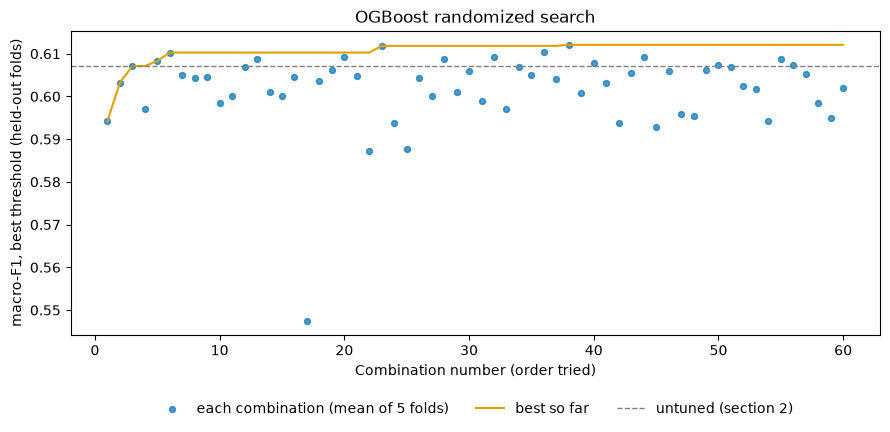

Untuned, scored the same way: 0.607

macro_f1_best_threshold by link function:
                 max   mean  count
link_function                     
cauchit        0.612  0.601     18
logit          0.609  0.605     19
probit         0.609  0.600     23

Best settings:
  base_learner__max_depth: 5
  base_learner__max_features: 0.663
  base_learner__min_samples_leaf: 346
  learning_rate: 0.0407
  link_function: cauchit
  n_estimators: 247


In [6]:
# Each combination's held-out macro-F1 (best threshold), in the order they were tried, and the best score so far
untuned_best_threshold_f1 = np.mean([best_threshold_macro_f1(y_train.iloc[valid_index], untuned_probabilities[valid_index])
                                     for _, valid_index in folds])

fig, ax = plt.subplots(figsize=(9, 4.5))
tried = results_df["mean_test_macro_f1_best_threshold"].to_numpy()
ax.scatter(np.arange(1, len(tried) + 1), tried, s=18, color="#0072B2", alpha=0.7, label="each combination (mean of 5 folds)")
ax.plot(np.arange(1, len(tried) + 1), np.maximum.accumulate(tried), color="#E69F00", label="best so far")
ax.axhline(untuned_best_threshold_f1, color="gray", ls="--", lw=1, label="untuned (section 2)")
ax.set_xlabel("Combination number (order tried)")
ax.set_ylabel("macro-F1, best threshold (held-out folds)")
ax.set_title("OGBoost randomized search")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

print(f"Untuned, scored the same way: {untuned_best_threshold_f1:.3f}")
print("\nmacro_f1_best_threshold by link function:")
print(search_results_df.groupby("link_function")["macro_f1_best_threshold"].agg(["max", "mean", "count"]).round(3).to_string())

best_params = search.best_params_
print("\nBest settings:")
for name, value in best_params.items():
    print(f"  {name}: {value:.4g}" if isinstance(value, float) else f"  {name}: {value}")

### Reading the Search
- **Best combination: 0.612** macro-F1 at its best threshold, vs. **0.607 for the untuned model** scored the same way (dashed line). Only about 15 of the 60 combinations beat the untuned model: its settings were already close to good.
- **Winning settings:** 247 trees, learning rate 0.041, depth-5 trees with at least 346 rows per leaf, `cauchit` link. All of the top 10 use large leaves (75 to 346 rows).
- **The link function matters little:** the best score per link is 0.612 (`cauchit`), 0.609 (`logit`) and 0.609 (`probit`). The top 10 span 0.609 to 0.612, within the fold-to-fold spread (about 0.008).
- **Little memorizing:** the best combination scores 0.628 on its training rows vs. 0.612 on held-out rows.

## 6. Tuned vs. Untuned
Both models use **their own Disrupted threshold**, chosen on the other 4 folds (section 7). This is how the final model is used, and how every tuned model's results are saved, so the scores are comparable across notebooks. The tuned score is slightly optimistic, since the settings were chosen on these same folds.

In [7]:
tuned_model = search.best_estimator_
tuned_probabilities = cross_val_predict(tuned_model, X_train, y_train, cv=folds, method="predict_proba", n_jobs=-1)
tuned_fold_scores = score_folds(y_train, tuned_probabilities, folds)   # default rule

# Each model with its own threshold, chosen on the other 4 folds and scored on the held-out fold
untuned_threshold_scores = cross_validated_threshold(y_train, untuned_probabilities, folds).drop(columns="threshold")
tuned_threshold_fold_scores = cross_validated_threshold(y_train, tuned_probabilities, folds)
tuned_threshold_scores = tuned_threshold_fold_scores.drop(columns="threshold")

# The 5 scores used throughout (same as the summary in section 9), with readable names
metric_labels = {"macro_f1": "Macro F1", "f1_disrupted": "Disrupted F1", "disrupted_precision": "Disrupted precision",
                 "disrupted_recall": "Disrupted recall", "disrupted_pr_auc": "Disrupted PR-AUC"}
shown = list(metric_labels)

comparison = pd.DataFrame({
    "Untuned": untuned_threshold_scores[shown].mean(),
    "Tuned": tuned_threshold_scores[shown].mean(),
}).rename(index=metric_labels)
comparison.round(3)

,Untuned,Tuned
Macro F1,0.597,0.608
Disrupted F1,0.344,0.364
Disrupted precision,0.305,0.328
Disrupted recall,0.399,0.411
Disrupted PR-AUC,0.327,0.320


### Reading the Comparison
Mean over the 5 folds.
- **Tuning improves macro-F1 by 0.011 (0.597 -> 0.608)** and Disrupted F1 from 0.344 to 0.364. Disrupted precision rises (0.305 -> 0.328), recall only slightly (0.399 -> 0.411).
- **Ranking of disruptions does not improve:** Disrupted PR-AUC 0.327 -> 0.320. The gain is in how well one threshold separates the statuses, not in recognizing more disruptions.

## 7. Choose the Disrupted Threshold
Same method as the other notebooks: Disrupted if its probability is at least the threshold, otherwise the more likely of Normal and Delayed. The threshold with the highest macro-F1 is chosen, and scored honestly by choosing it on the other 4 folds (`cross_validated_threshold`). The saved threshold is chosen on all training rows.

In [8]:
threshold_fold_scores = tuned_threshold_fold_scores   # from section 6
final_threshold = choose_threshold(y_train, tuned_probabilities)
chosen_scores = threshold_fold_scores[shown]

# Tuned model, mean over the 5 folds: highest probability wins vs. the chosen Disrupted threshold
threshold_comparison = pd.DataFrame({
    "Default rule": tuned_fold_scores[shown].mean(),
    "Chosen threshold": chosen_scores.mean(),
}).rename(index=metric_labels)
print("Threshold chosen in each fold (on the other 4 folds):", threshold_fold_scores["threshold"].tolist())
print("Final threshold (chosen on all training rows):", final_threshold)
threshold_comparison.round(3)

Threshold chosen in each fold (on the other 4 folds): [0.75, 0.75, 0.75, 0.73, 0.75]
Final threshold (chosen on all training rows): 0.75


,Default rule,Chosen threshold
Macro F1,0.546,0.608
Disrupted F1,0.271,0.364
Disrupted precision,0.166,0.328
Disrupted recall,0.742,0.411
Disrupted PR-AUC,0.320,0.320


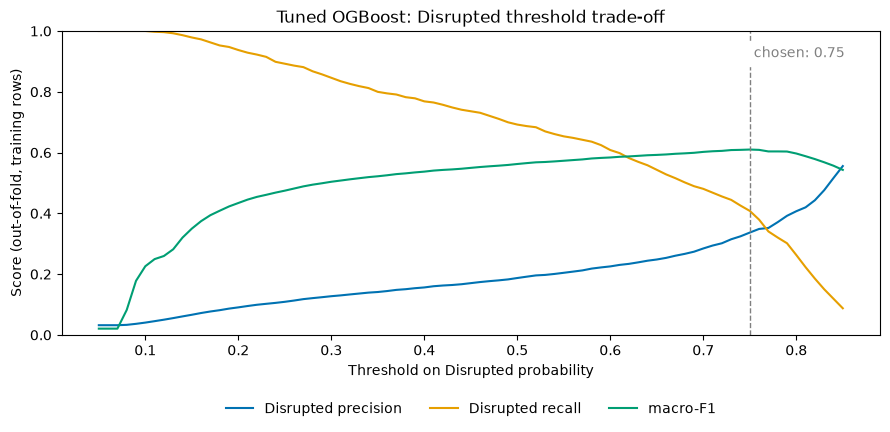

In [9]:
# The full trade-off for the tuned model (out-of-fold, all training rows)
trade_off = pd.DataFrame([
    {"threshold": t, **score_predictions(y_train, tuned_probabilities, t),
     "rows flagged Disrupted": int((predict_with_threshold(tuned_probabilities, t) == DISRUPTED).sum())}
    for t in THRESHOLDS
]).set_index("threshold")

# Plot only thresholds that still flag at least 100 rows: above that, precision is based on a handful of rows and jumps around
plotted = trade_off[trade_off["rows flagged Disrupted"] >= 100]

fig, ax = plt.subplots(figsize=(9, 4.5))
for column, color, label in [("disrupted_precision", "#0072B2", "Disrupted precision"),
                             ("disrupted_recall", "#E69F00", "Disrupted recall"),
                             ("macro_f1", "#009E73", "macro-F1")]:
    ax.plot(plotted.index, plotted[column], color=color, label=label)
ax.axvline(final_threshold, color="gray", ls="--", lw=1)
ax.text(final_threshold, 0.95, f" chosen: {final_threshold}", color="gray", va="top", backgroundcolor="white")
ax.set_xlabel("Threshold on Disrupted probability")
ax.set_ylabel("Score (out-of-fold, training rows)")
ax.set_ylim(0, 1)
ax.set_title("Tuned OGBoost: Disrupted threshold trade-off")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Alternative: a Recall Target
The highest threshold that still catches at least the target share of real disruptions, and what it costs in precision and false alarms.

In [10]:
recall_target_rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    meets_target = trade_off[trade_off["disrupted_recall"] >= target]
    if meets_target.empty:
        # Even the lowest threshold tried doesn't catch this share of disruptions
        recall_target_rows.append({"recall target": target, "threshold": "not reachable"})
        continue
    threshold = meets_target.index.max()
    row = trade_off.loc[threshold]
    caught = row["disrupted_recall"] * (y_train == DISRUPTED).sum()
    recall_target_rows.append({
        "recall target": target,
        "threshold": threshold,
        "disrupted_recall": row["disrupted_recall"],
        "disrupted_precision": row["disrupted_precision"],
        "macro_f1": row["macro_f1"],
        "false alarms per disruption caught": (row["rows flagged Disrupted"] - caught) / caught,
    })

pd.DataFrame(recall_target_rows).set_index("recall target").round(3)

,threshold,disrupted_recall,disrupted_precision,macro_f1,false alarms per disruption caught
recall target,,,,,
0.5,0.68,0.502,0.267,0.597,2.751
0.6,0.60,0.608,0.225,0.584,3.436
0.7,0.48,0.711,0.180,0.557,4.570
0.8,0.34,0.812,0.139,0.519,6.186
0.9,0.23,0.915,0.102,0.461,8.774


### Reading the Threshold Results
- **Threshold 0.75 improves macro-F1 by 0.062 over the default rule (0.546 -> 0.608).** The threshold chosen in each fold is very stable (0.73 to 0.75), and the final threshold is **0.75**.
- The trade-off: Disrupted precision doubles (0.17 -> 0.33), recall falls (0.74 -> 0.41); Disrupted F1 rises from 0.271 to 0.364. PR-AUC does not depend on the threshold, so it is unchanged.
- **Recall targets:** catching 50% of disruptions costs about 2.8 false alarms per disruption caught (threshold 0.68), 70% costs 4.6 (0.48) and 90% costs 8.8 (0.23). Almost the same as tuned LightGBM (2.7, 4.6 and 8.4).
- The plot stops at 0.85: higher thresholds flag fewer than 100 rows (none above 0.89), so precision there is based on a handful of rows and is just noise.

## 8. Save the Results
- `results/tuning/ogboost/`: the shared tuning format (best settings and threshold, fold scores at the chosen threshold, out-of-fold probabilities, all search results)
- `results/baseline/ogboost/`: the untuned model in the same format as the 03 baselines (default-rule fold scores with fit time, out-of-fold probabilities), so it can be compared with the other untuned models

In [11]:
folder = save_tuning_results(
    model_name="OGBoost",
    best_params=best_params,
    fold_scores_df=threshold_fold_scores,
    out_of_fold_probabilities=tuned_probabilities,
    train_df=train_df,
    threshold=final_threshold,
    search_results_df=search_results_df,
)
print("Saved to", folder)

# Untuned baseline, same layout as results/baseline/<model>/ from 03
baseline_folder = "../results/baseline/ogboost"
os.makedirs(baseline_folder, exist_ok=True)
untuned_fold_scores.assign(fit_seconds=fit_seconds).to_csv(os.path.join(baseline_folder, "cv_fold_scores.csv"))
baseline_probabilities_df = train_df[["date", "route_id", "route_status"]].copy()
for number, status in enumerate(STATUS_ORDER):
    baseline_probabilities_df[f"prob_{status.lower()}"] = untuned_probabilities[:, number]
baseline_probabilities_df.to_csv(os.path.join(baseline_folder, "out_of_fold_probabilities.csv"), index=False,
                                 date_format="%m/%d/%Y")
print("Saved to", baseline_folder)

Saved to ../results/tuning\ogboost
Saved to ../results/baseline/ogboost


## 9. Summary
Untuned vs. tuned OGBoost, and tuned OGBoost vs. tuned LightGBM (read from `results/tuning/lightgbm/cv_fold_scores.csv`). Mean over the 5 folds; every model with its own threshold, chosen on the other 4 folds. All use the same folds, so they can be compared fold by fold.

In [12]:
summary_columns = ["macro_f1", "f1_disrupted", "disrupted_precision", "disrupted_recall", "disrupted_pr_auc"]
lightgbm_fold_scores = pd.read_csv("../results/tuning/lightgbm/cv_fold_scores.csv", index_col="fold")

summary = pd.DataFrame({
    "OGBoost untuned": untuned_threshold_scores[summary_columns].mean(),
    f"OGBoost tuned (threshold {final_threshold})": tuned_threshold_scores[summary_columns].mean(),
    "LightGBM tuned": lightgbm_fold_scores[summary_columns].mean(),
    "OGBoost tuned - LightGBM tuned": (tuned_threshold_scores[summary_columns] - lightgbm_fold_scores[summary_columns]).mean(),
    "folds OGBoost better (of 5)": (tuned_threshold_scores[summary_columns] > lightgbm_fold_scores[summary_columns]).sum(),
})
summary.round(3)

,OGBoost untuned,OGBoost tuned (threshold 0.75),LightGBM tuned,OGBoost tuned - LightGBM tuned,folds OGBoost better (of 5)
macro_f1,0.597,0.608,0.602,0.006,3
f1_disrupted,0.344,0.364,0.350,0.014,3
disrupted_precision,0.305,0.328,0.330,-0.003,2
disrupted_recall,0.399,0.411,0.374,0.036,4
disrupted_pr_auc,0.327,0.320,0.327,-0.006,2


**Setup:** randomized search over 6 OGBoost settings (60 combinations), the same 5 folds as 03, balanced class weights (through `sample_weight`), settings chosen by macro-F1 at their best Disrupted threshold. The test set was not used.

**Results (mean over the 5 folds; each model with its own threshold, chosen on the other 4 folds)**

| | macro-F1 | Disrupted F1 | Disrupted precision | Disrupted recall | Disrupted PR-AUC |
|---|---|---|---|---|---|
| OGBoost untuned (400 trees, learning rate 0.05, depth 3) | 0.597 | 0.344 | 0.305 | 0.399 | **0.327** |
| **OGBoost tuned** (threshold 0.75) | **0.608** | **0.364** | 0.328 | **0.411** | 0.320 |
| LightGBM tuned (threshold 0.81) | 0.602 | 0.350 | **0.330** | 0.374 | **0.327** |

**What this means for us**
1. **Untuned OGBoost is already almost as good as tuned LightGBM** (macro-F1 0.597 vs. 0.602, same Disrupted PR-AUC 0.327): treating the statuses as ordered helps without any tuning.
2. **Tuning helps OGBoost only a little:** +0.011 macro-F1 (all 5 folds), and no better ranking of disruptions (PR-AUC 0.327 -> 0.320).
3. **Tuned OGBoost vs. tuned LightGBM: a tie.** +0.006 macro-F1 (better on 3 of 5 folds) and +0.036 Disrupted recall (4 of 5) at the same precision, but -0.006 PR-AUC. All differences are smaller than the fold-to-fold spread.
4. As for LightGBM, the Disrupted threshold (0.75) matters more than the settings: +0.062 macro-F1 over the default rule.

**Saved:** `results/tuning/ogboost/` (best settings, threshold 0.75, fold scores, out-of-fold probabilities, all search results) and `results/baseline/ogboost/` (untuned model, 03 format).

**Next steps**
- Add OGBoost to the comparison notebook (it reads `results/tuning/ogboost/` like the others).
- Score the chosen model **once** on the test set.